# Credit Card Fraud Detection

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os

In [2]:
Data  = pd.read_csv('data/interview case study.csv')
print(Data.shape)
Data.head()

(594643, 10)


,step,customer,age,gender,zipcodeOri,merchant,zipMerchant,category,amount,fraud
0,0,'C1093826151','4','M','28007','M348934600','28007','es_transportation',4.55,0
1,0,'C352968107','2','M','28007','M348934600','28007','es_transportation',39.68,0
2,0,'C2054744914','4','F','28007','M1823072687','28007','es_transportation',26.89,0
3,0,'C1760612790','3','M','28007','M348934600','28007','es_transportation',17.25,0
4,0,'C757503768','5','M','28007','M348934600','28007','es_transportation',35.72,0


## 1. Data Preprocessing

First I check the data types, missing values and how many unique values each column has.

In [3]:
Data.info()

<class 'pandas.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  str    
 2   age          594643 non-null  str    
 3   gender       594643 non-null  str    
 4   zipcodeOri   594643 non-null  str    
 5   merchant     594643 non-null  str    
 6   zipMerchant  594643 non-null  str    
 7   category     594643 non-null  str    
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), str(7)
memory usage: 45.4 MB


In [4]:
Data.isnull().sum()

step           0
customer       0
age            0
gender         0
zipcodeOri     0
merchant       0
zipMerchant    0
category       0
amount         0
fraud          0
dtype: int64

No missing values in any column, so there's nothing to fill.

In [5]:
Data.nunique()

step             180
customer        4112
age                8
gender             4
zipcodeOri         1
merchant          50
zipMerchant        1
category          15
amount         23767
fraud              2
dtype: int64

`zipcodeOri` and `zipMerchant` have only **1 unique value**, so they can't help the model. Dropping them.

In [6]:
Data= Data.drop(columns=['zipcodeOri','zipMerchant'])

All the text values are stored with quote marks (`'M'`, `'es_food'`), so I strip them.

In [7]:
text_columns = Data.select_dtypes(include=['object','string']).columns
for i in text_columns:
    Data[i] = Data[i].str.strip("'")

In [8]:
print(Data.shape)
Data.head()

(594643, 8)


,step,customer,age,gender,merchant,category,amount,fraud
0,0,C1093826151,4,M,M348934600,es_transportation,4.55,0
1,0,C352968107,2,M,M348934600,es_transportation,39.68,0
2,0,C2054744914,4,F,M1823072687,es_transportation,26.89,0
3,0,C1760612790,3,M,M348934600,es_transportation,17.25,0
4,0,C757503768,5,M,M348934600,es_transportation,35.72,0


## 2. EDA

### Target distribution
How many transactions are fraud?

In [9]:
Fraud_Percent= Data['fraud'].mean()*100
print(f"{Fraud_Percent:.2f}%")

1.21%


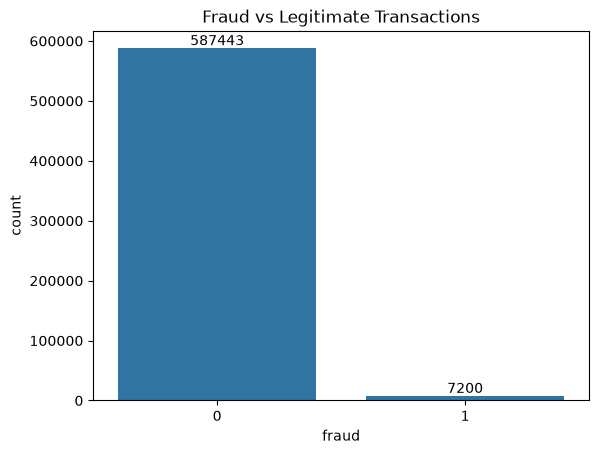

In [10]:
ax = sns.countplot(x='fraud', data=Data)
ax.bar_label(ax.containers[0])           
plt.title('Fraud vs Legitimate Transactions')
plt.savefig('images/Transactions.png', dpi=300, bbox_inches='tight')
plt.show()


Only **1.21%** of transactions are fraud (7,200 out of 594,643). The data is very imbalanced, so accuracy will be misleading and I need to handle the imbalance later.

### Amount
Comparing the amounts of fraud vs legit transactions.

In [11]:
Data.groupby('fraud')['amount'].describe()

,count,mean,std,min,25%,50%,75%,max
fraud,,,,,,,,
0,587443.0,31.847230,31.470876,0.00,13.59,26.610,41.8950,2144.86
1,7200.0,530.926551,835.587112,0.03,159.98,319.175,548.9775,8329.96


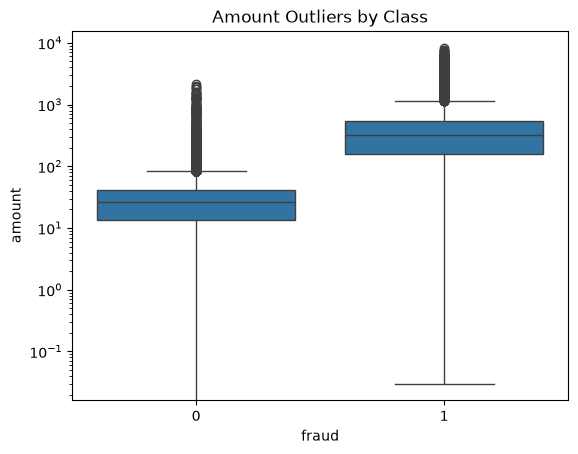

In [12]:
sns.boxplot(x='fraud', y='amount', data=Data)
plt.yscale('log')
plt.title('Amount Outliers by Class')
plt.savefig('images/amount_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

- Median legit amount is about €27, median fraud is €319, so fraud is about **12x bigger**.
- The highest legit amount is €2,145, so every transaction above that is fraud.
- I'm keeping the outliers, because in fraud detection the outliers are often the fraud itself.

### Category

In [13]:
cat = Data.groupby('category')['fraud'].agg(['count', 'mean']).sort_values('mean', ascending=False)
cat['mean'] = cat['mean'] * 100
cat.columns = ['transactions', 'fraud rate %']
print(cat)

                       transactions  fraud rate %
category                                         
es_leisure                      499     94.989980
es_travel                       728     79.395604
es_sportsandtoys               4002     49.525237
es_hotelservices               1744     31.422018
es_otherservices                912     25.000000
es_home                        1986     15.206445
es_health                     16133     10.512614
es_tech                        2370      6.666667
es_wellnessandbeauty          15086      4.759380
es_hyper                       6098      4.591669
es_barsandrestaurants          6373      1.882944
es_fashion                     6454      1.797335
es_contents                     885      0.000000
es_food                       26254      0.000000
es_transportation            505119      0.000000


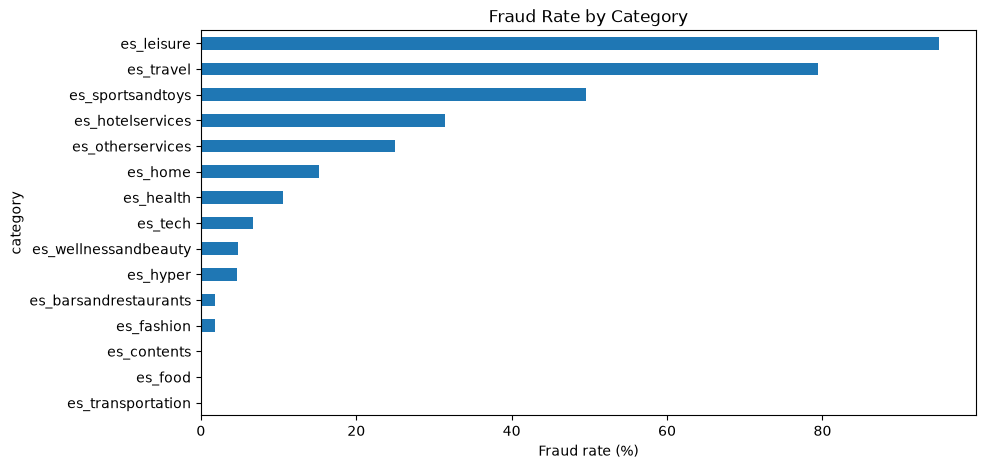

In [14]:
cat['fraud rate %'].plot(kind='barh', figsize=(10, 5))
plt.gca().invert_yaxis()
plt.xlabel('Fraud rate (%)')
plt.title('Fraud Rate by Category')
plt.savefig('images/fraud_by_category.png', dpi=300, bbox_inches='tight')


- Fraud is concentrated in a few categories: **leisure 95%, travel 79%, sports & toys 50%**.
- Transportation, food and contents have **0% fraud**. Transportation alone is 505,119 transactions (85% of the data).

### Merchants

In [15]:
merch = Data.groupby('merchant')['fraud'].agg(['count', 'mean']).sort_values('mean', ascending=False)
print((merch['mean'] == 0).sum())

20


20 of the 50 merchants have zero fraud, so merchant is a useful feature. The risk: the model learns merchants by name, so a new merchant would be unknown to it.

### Age and gender

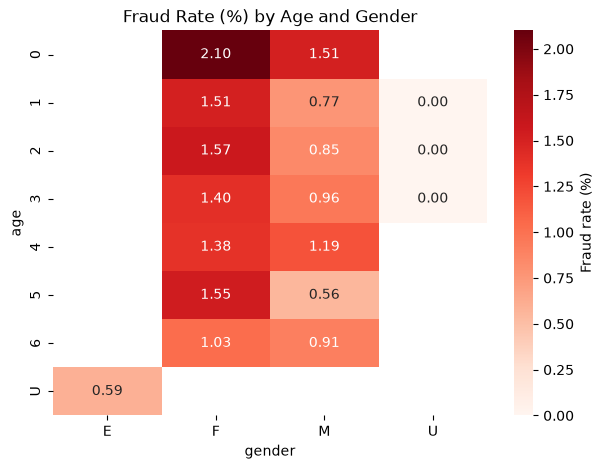

In [16]:
pivot = Data.pivot_table(index='age', columns='gender', values='fraud', aggfunc='mean') * 100

plt.figure(figsize=(7, 5))
sns.heatmap(pivot, annot=True, fmt='.2f', cmap='Reds', cbar_kws={'label': 'Fraud rate (%)'})
plt.title('Fraud Rate (%) by Age and Gender')
plt.savefig('images/fraud_heatmap_age_gender.png', dpi=300, bbox_inches='tight')

All groups are between 0% and 2.1% fraud, so age and gender only have a small effect. Enterprise accounts (E) only show up with unknown age (U), which makes sense because a business has no age.

### Time

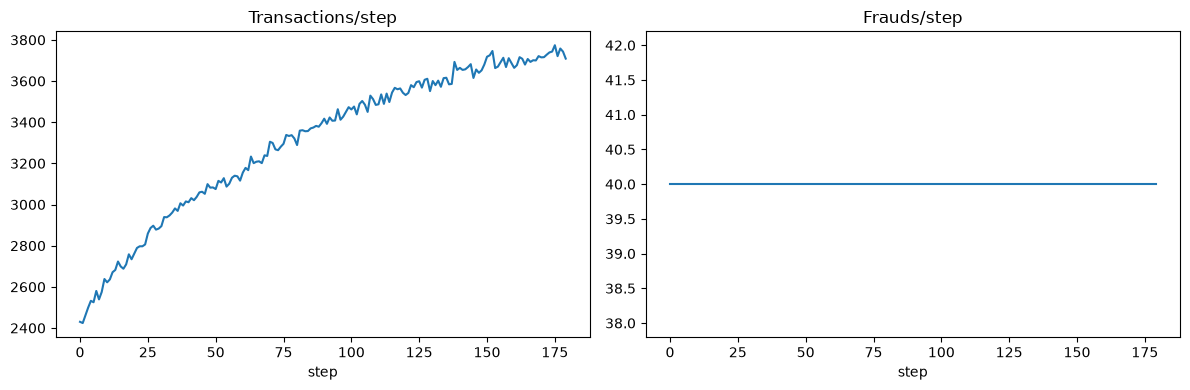

In [17]:
per_step = Data.groupby('step')['fraud'].agg(['size', 'sum', 'mean'])
per_step.columns = ['transactions', 'frauds', 'fraud_rate']

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
per_step['transactions'].plot(ax=axes[0], title='Transactions/step')
per_step['frauds'].plot(ax=axes[1], title='Frauds/step')
plt.tight_layout()
plt.savefig('images/trend_over_time.png', dpi=400, bbox_inches='tight')

There are **exactly 40 frauds in every step**, while the number of transactions keeps growing. Real fraud doesn't behave like this, so the data is probably simulated, and time won't help predict fraud.

### EDA summary
- 1.2% fraud, so the data is imbalanced
- Fraud amounts are much higher than legit ones
- Category is the strongest pattern
- Some merchants are high risk
- Age, gender and time barely matter

## 3. Feature Engineering

### Hour of day
The brief says 1 step = 1 hour, so I created `clock = step % 24`.

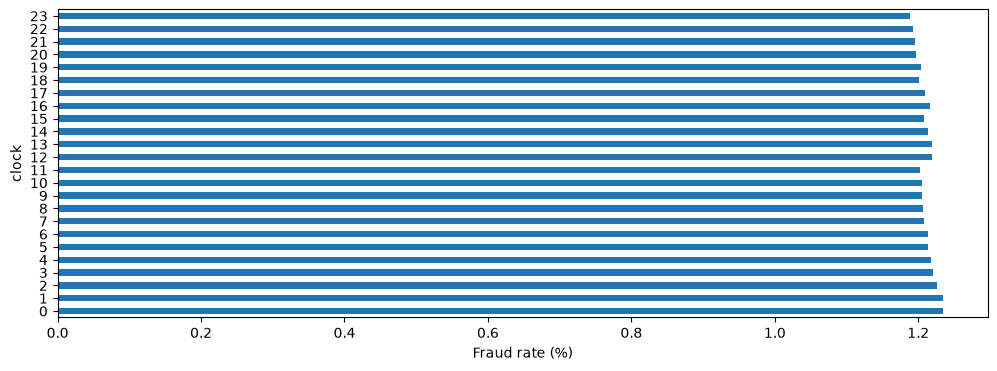

In [18]:
Data['clock'] = Data['step'] % 24
(Data.groupby('clock')['fraud'].mean() * 100).plot(kind='barh', figsize=(12, 4))
plt.xlabel('Fraud rate (%)')
plt.show()

The fraud rate is flat (about 1.2%) across all hours, so this feature has no real signal. I kept it anyway and report it.

### Log amount
`amount` is very skewed. Checking the skewness before and after log.

In [19]:
print(Data['amount'].skew()) 
print(np.log1p(Data['amount']).skew())

32.365838150883036
-0.4214331820892838


Skewness goes from 32.4 to -0.4. This mainly helps Logistic Regression; tree models don't care about scale. I used `log1p` because some amounts are 0.

In [20]:
Data['log_amount'] = np.log1p(Data['amount'])


### Customer behaviour features
A €200 purchase is suspicious for a customer who usually spends €20, but normal for one who spends €250. So I created:
- `cust_mean_amt`: the customer's average spend
- `amt_vs_cust_mean`: this amount divided by the customer's average
- `cust_ts_count`: how many transactions the customer has

In [21]:
cust = Data.groupby('customer')['amount']
Data['cust_mean_amt']    = cust.transform('mean')               
Data['amt_vs_cust_mean'] = Data['amount'] / Data['cust_mean_amt']   
Data['cust_ts_count']    = cust.transform('count')
print(Data.groupby(pd.qcut(Data['amt_vs_cust_mean'], 5))['fraud'].mean() * 100)

amt_vs_cust_mean
(-0.001, 0.31]     0.495253
(0.31, 0.62]       0.464987
(0.62, 0.957]      0.490208
(0.957, 1.407]     0.497780
(1.407, 94.383]    4.105811
Name: fraud, dtype: float64


The 20% most unusual purchases have **4.1% fraud**, vs about 0.5% for the rest, so the feature works.

Note: the averages use all of a customer's transactions. In a real system they should only use past ones.

### Encoding and X / Y split
- One-hot encoding for age, gender, category and merchant: there's no order between the values, and gender has 4 values, not 2.
- `drop_first=True` removes the redundant column.
- Dropped `customer` (4,112 IDs, the model would just memorize them), `step` (replaced by `clock`) and `amount` (replaced by `log_amount`).

In [22]:
X= Data.drop(columns=['fraud','customer','amount','step'])
X= pd.get_dummies(X, columns=['age','gender','category','merchant'], drop_first=True, dtype=int)
Y= Data['fraud']
print(X.shape, Y.shape)

(594643, 78) (594643,)


## 4. Model Selection

### Why not accuracy?
Testing a "model" that always predicts not fraud:

In [23]:
from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

pred = np.zeros(len(Y)) 
print('Accuracy :', accuracy_score(Y, pred))
print('Recall   :', recall_score(Y, pred))
print('Precision:', precision_score(Y, pred, zero_division=0))
print('F1       :', f1_score(Y, pred))

Accuracy : 0.987891894800746
Recall   : 0.0
Precision: 0.0
F1       : 0.0


98.8% accuracy but **0 recall**: it catches no fraud at all. So I use **PR-AUC** as the main metric, and also report F1, precision, recall and ROC-AUC.

Models:
- **Logistic Regression**: simple baseline
- **Random Forest**: catches combinations like "travel + high amount"
- **XGBoost**: usually the strongest on tabular data, with built-in imbalance handling

## 5. Train / Test Split
80/20 split with `stratify` so both sets keep 1.2% fraud. `random_state=42` so the results are reproducible.

In [24]:
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)
print(X_train.shape, X_test.shape, Y_train.shape, Y_test.shape)

(475714, 78) (118929, 78) (475714,) (118929,)


### Scaling
Only needed for Logistic Regression (trees don't care about scale). The scaler is fitted on the training data only and then applied to the test data, to avoid leakage.

In [25]:
from sklearn.preprocessing import StandardScaler
num_cols = ['log_amount', 'cust_mean_amt', 'amt_vs_cust_mean', 'cust_ts_count', 'clock']
scaler = StandardScaler()
scaler.fit(X_train[num_cols])

X_train_a= X_train.copy()
X_test_a = X_test.copy()
X_train_a[num_cols] = scaler.transform(X_train[num_cols])
X_test_a[num_cols] = scaler.transform(X_test[num_cols])


## 6. Model Training & Handling Imbalance
Two ways to handle the imbalance:
- **Class weights**: a missed fraud costs more during training (`class_weight='balanced'`, and `scale_pos_weight` ≈ 82 for XGBoost)
- **SMOTE**: creates synthetic fraud rows until the classes are equal

In [26]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(max_iter=100,class_weight='balanced')
lr.fit(X_train_a, Y_train)
print(lr.n_iter_)


[52]


In [27]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, class_weight='balanced', n_jobs=-1, random_state=42)
rf.fit(X_train, Y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: {""balanced"", ""balanced_subsample""}, dict or list of dicts, default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``The ""balanced_subsample"" mode is the same as ""balanced"" except thatweights are computed based on the bootstrap sample for every treegrown.For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_fe

In [28]:
from xgboost import XGBClassifier
xgb=XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6, eval_metric='aucpr',scale_pos_weight=(Y_train == 0).sum() / (Y_train == 1).sum(), n_jobs=-1, random_state=42)
xgb.fit(X_train, Y_train)

,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'aucpr'
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


SMOTE is inside an imblearn `Pipeline`, so it only runs during training and the test set stays real. No `scale_pos_weight` here, because SMOTE already balances the data.

In [29]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

smote_xgb = Pipeline([
    ('smote', SMOTE(random_state=42)),
    ('xgb', XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.1,eval_metric='aucpr', n_jobs=-1, random_state=42))
])
smote_xgb.fit(X_train, Y_train)

,steps,"[('smote', ...), ('xgb', ...)]"
,transform_input,None
,memory,None
,verbose,False
Name,Type,Value
classes_,"ndarray[int64](2,)","[0,1]"
feature_names_in_,"ndarray[object](78,)","['clock','log_amount','cust_mean_amt',...,'merchant_M933210764', 'merchant_M97925176','merchant_M980657600']"
n_features_in_,int,78
,random_state,42
,sampling_strategy,'auto'
,k_neighbors,5


In [30]:
print(xgb.predict_proba(X_test[:5]))

[[9.9999911e-01 8.9770305e-07]
 [9.9997556e-01 2.4467225e-05]
 [9.9975830e-01 2.4167087e-04]
 [9.9998295e-01 1.7062246e-05]
 [9.9999046e-01 9.5210180e-06]]


## 7. Model Evaluation

In [31]:
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
            precision_score, recall_score, confusion_matrix)

models = {
    'Logistic Regression': (lr, X_test_a),     
    'Random Forest':       (rf, X_test),
    'XGBoost (weights)':   (xgb, X_test),
    'XGBoost (SMOTE)':     (smote_xgb, X_test),
}

results, probs = [], {}
for name, (model, Xt) in models.items():
    p = model.predict_proba(Xt)[:, 1]         
    pred = (p >= 0.5).astype(int)              
    probs[name] = p
    tn, fp, fn, tp = confusion_matrix(Y_test, pred).ravel()
    results.append({
        'Model': name,
        'ROC-AUC':   roc_auc_score(Y_test, p),
        'PR-AUC':    average_precision_score(Y_test, p),
        'Precision': precision_score(Y_test, pred),
        'Recall':    recall_score(Y_test, pred),
        'F1':        f1_score(Y_test, pred),
        'Frauds caught': tp, 'Frauds missed': fn, 'False alarms': fp,
    })

results_Data = pd.DataFrame(results).set_index('Model').round(3)
results_Data

,ROC-AUC,PR-AUC,Precision,Recall,F1,Frauds caught,Frauds missed,False alarms
Model,,,,,,,,
Logistic Regression,0.998,0.853,0.311,0.983,0.473,1416,24,3130
Random Forest,0.998,0.915,0.507,0.965,0.664,1390,50,1354
XGBoost (weights),0.998,0.931,0.484,0.966,0.645,1391,49,1481
XGBoost (SMOTE),0.998,0.928,0.799,0.882,0.838,1270,170,320


- ROC-AUC is about 0.998 for every model, so it can't separate them. PR-AUC can.
- Tree models beat Logistic Regression (0.85 to 0.93), because fraud depends on combinations of features.
- XGBoost with class weights has the best PR-AUC (0.931). SMOTE is almost the same (0.928).
- SMOTE has a higher F1 at 0.5, but that comes from where its probabilities fall around the 0.5 cutoff, not from better ranking.
- I go with **XGBoost (class weights)**: simpler, and trained only on real data.

## 8. Model Interpretation (SHAP)

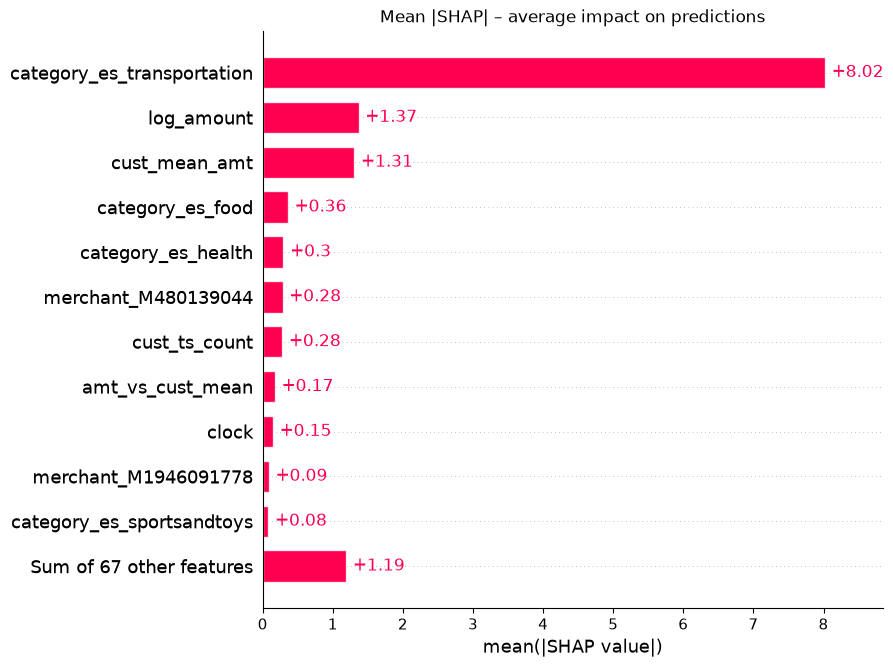

In [34]:
import shap

X_sample = X_test.sample(3000, random_state=42)  
explainer = shap.TreeExplainer(xgb)
sv = explainer(X_sample)                           

shap.plots.bar(sv, max_display=12, show=False)
plt.title('Mean |SHAP| – average impact on predictions')
plt.show()

- Category (transportation) is by far the strongest feature.
- Then the amount and the customer's usual spend.
- A few merchants matter too.
- Age and gender are not in the top features, so the model doesn't rely on demographics.
- `clock` gets a small weight even though its fraud rate is flat, which is a sign of slight noise fitting.

## 9. Fine-tuning
RandomizedSearchCV: 10 random combinations, 3-fold cross-validation, scored on PR-AUC. Random search is much faster than trying every combination.

In [33]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    'n_estimators':  [200, 400, 600],
    'max_depth':     [4, 6, 8],
    'learning_rate': [0.03, 0.05, 0.1],
    'subsample':     [0.7, 0.85, 1.0],
}

search = RandomizedSearchCV(
    XGBClassifier(scale_pos_weight=(Y_train == 0).sum() / (Y_train == 1).sum(), eval_metric='aucpr', n_jobs=-1, random_state=42),
    param_dist, n_iter=10, scoring='average_precision', cv=3, random_state=42, verbose=1
)
search.fit(X_train, Y_train)
best = search.best_estimator_
print('Best params:', search.best_params_)

p = best.predict_proba(X_test)[:, 1]
pred = (p >= 0.5).astype(int)
print('ROC-AUC:', round(roc_auc_score(Y_test, p), 4))
print('PR-AUC :', round(average_precision_score(Y_test, p), 4))
print('F1     :', round(f1_score(Y_test, pred), 4))
print(confusion_matrix(Y_test, pred))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best params: {'subsample': 0.85, 'n_estimators': 600, 'max_depth': 6, 'learning_rate': 0.1}
ROC-AUC: 0.9983
PR-AUC : 0.9304
F1     : 0.7923
[[116911    578]
 [   116   1324]]


- Best params: 600 trees, depth 6, learning rate 0.1, subsample 0.85.
- PR-AUC stayed about the same (0.931 to 0.930), so the ranking didn't really improve.
- But at the 0.5 threshold, false alarms dropped from 1,481 to **578**, and it still catches **92%** of fraud (1,324 of 1,440).
- **Final model: tuned XGBoost.**
## 10. Conclusion & Recommendations
- Add extra verification for leisure, travel, sports & toys and hotel purchases above a set amount.
- Flag purchases far above the customer's usual spend.
- Review the high-risk merchants.
- Keep low friction on transportation and food (0% fraud).